Carga `train.csv` y el diccionario de datos, y lo compara con las cifras del E1: dimensiones, `sii` faltante, clases, tipos, columnas PCIAT, faltantes por columna y participantes con actigrafía. El `crosstab` final muestra que `sii` falta exactamente cuando falta el PCIAT total (causa administrativa).

In [32]:
import os
import numpy as np
import pandas as pd

import kagglehub

path = kagglehub.competition_download(
    "child-mind-institute-problematic-internet-use"
)
print("Contenido de la carpeta:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "train.csv"))
dic = pd.read_csv(os.path.join(path, "data_dictionary.csv"))

# --- 1) Dimensiones y verificación contra el E1 ---
print(f"Forma de train.csv: {df.shape}  (E1: 3960 x 82)")
print(f"Sin etiqueta: {df['sii'].isna().sum()} ({df['sii'].isna().mean()*100:.2f}%)  (E1: 1224, 30.91%)")
print(f"Etiquetadas:  {df['sii'].notna().sum()}  (E1: 2736)")
print("\nDistribución de sii (etiquetadas):")
print(df["sii"].value_counts().sort_index())
print((df["sii"].value_counts(normalize=True).sort_index() * 100).round(2))

# --- 2) Tipos de columnas ---
print("\nTipos de dato:\n", df.dtypes.value_counts())
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("\nColumnas categóricas (incluye 'id'):", cat_cols)

# --- 3) Columnas potencialmente problemáticas ---
pciat_cols = [c for c in df.columns if "PCIAT" in c]
print(f"\nColumnas PCIAT ({len(pciat_cols)}):", pciat_cols)

# --- 4) Faltantes por columna ---
miss = (df.isna().mean() * 100).sort_values(ascending=False)
print("\nTop 15 columnas con más faltantes (%):")
print(miss.head(15).round(1))
print(f"\nColumnas con >70% faltantes: {(miss > 70).sum()}")

# --- 5) Actigrafía: ¿quiénes tienen serie temporal? ---
series_dir = os.path.join(path, "series_train.parquet")
ids_con_serie = {d.split("=")[1] for d in os.listdir(series_dir) if d.startswith("id=")}
df["has_actigraphy"] = df["id"].isin(ids_con_serie).astype(int)
print(f"\nParticipantes con actigrafía: {df['has_actigraphy'].sum()} "
      f"({df['has_actigraphy'].mean()*100:.2f}%)  (E1: 996, 25.15%)")

# --- 6) ¿Por qué falta sii? Relación con el PCIAT total ---
print("\nsii faltante vs PCIAT_Total faltante:")
print(pd.crosstab(df["sii"].isna(), df["PCIAT-PCIAT_Total"].isna(),
                  rownames=["sii NaN"], colnames=["PCIAT_Total NaN"]))

Contenido de la carpeta: ['data_dictionary.csv', 'sample_submission.csv', 'series_test.parquet', 'series_train.parquet', 'test.csv', 'train.csv']
Forma de train.csv: (3960, 82)  (E1: 3960 x 82)
Sin etiqueta: 1224 (30.91%)  (E1: 1224, 30.91%)
Etiquetadas:  2736  (E1: 2736)

Distribución de sii (etiquetadas):
sii
0.0    1594
1.0     730
2.0     378
3.0      34
Name: count, dtype: int64
sii
0.0    58.26
1.0    26.68
2.0    13.82
3.0     1.24
Name: proportion, dtype: float64

Tipos de dato:
 float64    68
object     12
int64       2
Name: count, dtype: int64

Columnas categóricas (incluye 'id'): ['id', 'Basic_Demos-Enroll_Season', 'CGAS-Season', 'Physical-Season', 'Fitness_Endurance-Season', 'FGC-Season', 'BIA-Season', 'PAQ_A-Season', 'PAQ_C-Season', 'PCIAT-Season', 'SDS-Season', 'PreInt_EduHx-Season']

Columnas PCIAT (22): ['PCIAT-Season', 'PCIAT-PCIAT_01', 'PCIAT-PCIAT_02', 'PCIAT-PCIAT_03', 'PCIAT-PCIAT_04', 'PCIAT-PCIAT_05', 'PCIAT-PCIAT_06', 'PCIAT-PCIAT_07', 'PCIAT-PCIAT_08', 'PCIAT-

## 2. Test separado y esquema de validación
Deja solo las muestras etiquetadas, elimina las columnas PCIAT y `id` (control de fuga), separa un 20% estratificado como **test (no se toca hasta el final)** y quita las columnas con más de 70% de faltantes (calculado solo en entrenamiento). Define `cv` (5-fold estratificado repetido 3 veces) y muestra cuántas muestras de la clase 3 caen en cada fold.

In [8]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

SEED = 42

# --- 1) Solo muestras etiquetadas ---
df_lab = df[df["sii"].notna()].copy()
df_lab["sii"] = df_lab["sii"].astype(int)

# --- 2) Metadatos aparte (los usaremos en la Fase de actigrafía) ---
meta = df_lab[["id", "has_actigraphy"]]

# --- 3) Control de fuga: PCIAT (22 columnas, incluye PCIAT-Season) + id ---
leakage_cols = pciat_cols + ["id"]
y = df_lab["sii"]
X = df_lab.drop(columns=leakage_cols + ["sii", "has_actigraphy"])
print(f"Predictores tras control de fuga: {X.shape[1]}  (esperado: 58)")

# --- 4) Split estratificado 80/20 ---
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
meta_tr, meta_te = meta.loc[X_tr.index], meta.loc[X_te.index]

# --- 5) Filtro de columnas con >70% faltantes (calculado SOLO en entrenamiento) ---
miss_tr = X_tr.isna().mean()
cols_high_missing = miss_tr[miss_tr > 0.70].index.tolist()
print(f"\nColumnas eliminadas por >70% faltantes ({len(cols_high_missing)}):")
print(miss_tr[cols_high_missing].sort_values(ascending=False).round(3))

X_tr = X_tr.drop(columns=cols_high_missing)
X_te = X_te.drop(columns=cols_high_missing)

# --- 6) Listas de columnas por tipo ---
cat_features = X_tr.select_dtypes(include=["object", "category"]).columns.tolist()
num_features = X_tr.select_dtypes(include="number").columns.tolist()
print(f"\nPredictores finales: {X_tr.shape[1]}  (esperado: 52)")
print(f"  Numéricos: {len(num_features)} (esperado: 43) | Categóricos: {len(cat_features)} (esperado: 9)")

# --- 7) Distribución de clases por partición ---
resumen = pd.DataFrame({
    "train_n": y_tr.value_counts().sort_index(),
    "train_%": (y_tr.value_counts(normalize=True).sort_index() * 100).round(2),
    "test_n": y_te.value_counts().sort_index(),
    "test_%": (y_te.value_counts(normalize=True).sort_index() * 100).round(2),
})
print("\n", resumen)
print(f"\nActigrafía en train: {meta_tr['has_actigraphy'].sum()} | en test: {meta_te['has_actigraphy'].sum()}")

# --- 8) Esquema de validación: 5-fold estratificado repetido 3 veces ---
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

# Cuántas muestras de la clase 3 caen en cada fold de validación (primer repeat)
print("\nClase 3 en validación, por fold:")
for i, (tr_idx, va_idx) in enumerate(cv.split(X_tr, y_tr)):
    if i >= 5:
        break
    print(f"  Fold {i+1}: train={int((y_tr.iloc[tr_idx]==3).sum())}, val={int((y_tr.iloc[va_idx]==3).sum())}")

Predictores tras control de fuga: 58  (esperado: 58)

Columnas eliminadas por >70% faltantes (6):
PAQ_A-Season                    0.867
PAQ_A-PAQ_A_Total               0.867
Physical-Waist_Circumference    0.826
Fitness_Endurance-Time_Sec      0.735
Fitness_Endurance-Time_Mins     0.735
Fitness_Endurance-Max_Stage     0.734
dtype: float64

Predictores finales: 52  (esperado: 52)
  Numéricos: 43 (esperado: 43) | Categóricos: 9 (esperado: 9)

      train_n  train_%  test_n  test_%
sii                                  
0       1275    58.27     319   58.21
1        584    26.69     146   26.64
2        302    13.80      76   13.87
3         27     1.23       7    1.28

Actigrafía en train: 794 | en test: 202

Clase 3 en validación, por fold:
  Fold 1: train=22, val=5
  Fold 2: train=21, val=6
  Fold 3: train=21, val=6
  Fold 4: train=22, val=5
  Fold 5: train=22, val=5


## 3. Sesgo de selección de las muestras sin `sii`
Responde si las etiquetas faltantes son aleatorias. Se hace en tres pasos: pruebas univariadas (KS para numéricas y V de Cramér para categóricas, con corrección FDR), clasificadores que predicen `missing_sii`, y diagnósticos que separan patrón de ausencia de valores observados.

**3.1 Pruebas univariadas.** Compara etiquetados y no etiquetados variable por variable con tamaño de efecto y p-valor corregido.

In [9]:
from scipy.stats import ks_2samp, chi2_contingency

# Base completa (3,960): sin PCIAT, sin id, sin sii
df_all = df.copy()
df_all["missing_sii"] = df_all["sii"].isna().astype(int)
Xa = df_all.drop(columns=pciat_cols + ["id", "sii", "missing_sii", "has_actigraphy"])
ma = df_all["missing_sii"]

num_a = Xa.select_dtypes(include="number").columns.tolist()
cat_a = Xa.select_dtypes(include=["object", "category"]).columns.tolist()
print(f"Predictores: {Xa.shape[1]} | numéricos: {len(num_a)} | categóricos: {len(cat_a)}  (esperado: 58 | 48 | 10)")

def bh_fdr(p):
    """Corrección Benjamini-Hochberg."""
    p = np.asarray(p, float); n = len(p)
    order = np.argsort(p)
    adj = p[order] * n / np.arange(1, n + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(n); out[order] = np.clip(adj, 0, 1)
    return out

rows = []
for c in Xa.columns:
    lab, unl = Xa.loc[ma == 0, c], Xa.loc[ma == 1, c]
    row = {"variable": c,
           "miss_lab_%": lab.isna().mean() * 100,
           "miss_unlab_%": unl.isna().mean() * 100}
    if c in num_a:
        a, b = lab.dropna(), unl.dropna()
        if len(a) > 10 and len(b) > 10:
            r = ks_2samp(a, b)
            row.update(tipo="num", efecto=r.statistic, p=r.pvalue)   # efecto = D de KS
    else:
        tab = pd.crosstab(ma, Xa[c].fillna("Missing"))
        chi2, p, _, _ = chi2_contingency(tab)
        v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
        row.update(tipo="cat", efecto=v, p=p)                        # efecto = V de Cramér
    rows.append(row)

res = pd.DataFrame(rows)
ok = res["p"].notna()
res.loc[ok, "p_FDR"] = bh_fdr(res.loc[ok, "p"].values)
res["dif_miss_pp"] = res["miss_unlab_%"] - res["miss_lab_%"]
res = res.sort_values("efecto", ascending=False)

print("\nTop 15 variables por tamaño de efecto (labeled vs unlabeled):")
print(res[["variable", "tipo", "efecto", "p_FDR", "miss_lab_%", "miss_unlab_%"]].head(15).round(3).to_string(index=False))

print(f"\nVariables con p_FDR<0.05: {(res['p_FDR'] < 0.05).sum()} de {ok.sum()}")
print(f"Variables con efecto >= 0.10 (no despreciable): {(res['efecto'] >= 0.10).sum()}")

print("\nColumnas cuya tasa de faltantes más difiere entre grupos (pp):")
print(res.reindex(res["dif_miss_pp"].abs().sort_values(ascending=False).index)
        [["variable", "miss_lab_%", "miss_unlab_%", "dif_miss_pp"]].head(10).round(1).to_string(index=False))

# Variables clave: edad, sexo y proxies de severidad
focales = ["Basic_Demos-Age", "Basic_Demos-Sex", "PreInt_EduHx-computerinternet_hoursday",
           "CGAS-CGAS_Score", "Physical-BMI", "SDS-SDS_Total_T"]
print("\nVariables focales:")
print(res[res["variable"].isin(focales)][["variable", "efecto", "p_FDR"]].round(4).to_string(index=False))

Predictores: 58 | numéricos: 48 | categóricos: 10  (esperado: 58 | 48 | 10)

Top 15 variables por tamaño de efecto (labeled vs unlabeled):
                   variable tipo  efecto  p_FDR  miss_lab_%  miss_unlab_%
                 SDS-Season  cat   0.829  0.000       7.639        92.565
                CGAS-Season  cat   0.662  0.000      14.401        82.598
                 FGC-Season  cat   0.508  0.000       3.253        42.892
        PreInt_EduHx-Season  cat   0.492  0.000       0.621        32.925
            Physical-Season  cat   0.457  0.000       5.154        41.585
   Fitness_Endurance-Season  cat   0.415  0.000      53.947        96.078
                 BIA-Season  cat   0.402  0.000      32.602        75.408
               PAQ_C-Season  cat   0.280  0.000      47.368        77.042
            FGC-FGC_CU_Zone  num   0.279  0.000      31.140        67.484
Fitness_Endurance-Time_Mins  num   0.253  0.441      73.392        99.020
Fitness_Endurance-Max_Stage  num   0.248  0.456

**3.2 Clasificador de `missing_sii`.** Mide con AUC (CV 5×2) cuánto se puede predecir la ausencia de etiqueta: solo con edad y sexo, y con todas las covariables (LogReg e HistGB). Termina con la importancia por permutación de las variables.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.inspection import permutation_importance

Xc = Xa.copy()
Xc[cat_a] = Xc[cat_a].fillna("Missing")        # NaN en temporada = instrumento no aplicado

def build(cols_num, cols_cat, modelo):
    if modelo == "logreg":
        pre = ColumnTransformer([
            ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                              ("sc", StandardScaler())]), cols_num),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat)])
        clf = LogisticRegression(max_iter=2000, C=0.5)
    else:  # HGB maneja NaN de forma nativa
        pre = ColumnTransformer([
            ("num", "passthrough", cols_num),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cols_cat)])
        clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                             max_iter=200, random_state=SEED)
    return Pipeline([("pre", pre), ("clf", clf)])

cv_sel = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

# "Basic_Demos-Sex" es numérica (0/1) en este dataset
cols_demo_num = ["Basic_Demos-Age", "Basic_Demos-Sex"]

print("AUC para predecir missing_sii (0.5 = sin patrón):")
aucs = {}
s = cross_val_score(build(cols_demo_num, [], "logreg"), Xc, ma, cv=cv_sel, scoring="roc_auc")
aucs["Solo edad y sexo"] = s; print(f"  Solo edad y sexo (LogReg)    : {s.mean():.3f} ± {s.std():.3f}")
for nombre, modelo in [("Todas, LogReg", "logreg"), ("Todas, HistGB", "hgb")]:
    s = cross_val_score(build(num_a, cat_a, modelo), Xc, ma, cv=cv_sel, scoring="roc_auc")
    aucs[nombre] = s; print(f"  {nombre:<29}: {s.mean():.3f} ± {s.std():.3f}")

# ¿Qué variables generan el patrón? (permutation importance en hold-out)
Xa_tr, Xa_va, ma_tr, ma_va = train_test_split(Xc, ma, test_size=0.3, stratify=ma, random_state=SEED)
m = build(num_a, cat_a, "hgb").fit(Xa_tr, ma_tr)
pi = permutation_importance(m, Xa_va, ma_va, scoring="roc_auc", n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=Xa_va.columns).sort_values(ascending=False)
print("\nTop 10 variables por importancia (caída de AUC al permutar):")
print(imp.head(10).round(4))

AUC para predecir missing_sii (0.5 = sin patrón):
  Solo edad y sexo (LogReg)    : 0.540 ± 0.016
  Todas, LogReg                : 0.984 ± 0.006
  Todas, HistGB                : 0.989 ± 0.005

Top 10 variables por importancia (caída de AUC al permutar):
SDS-SDS_Total_Raw                         0.1149
CGAS-CGAS_Score                           0.0191
FGC-Season                                0.0028
Basic_Demos-Age                           0.0024
PreInt_EduHx-computerinternet_hoursday    0.0021
PAQ_C-PAQ_C_Total                         0.0010
PAQ_A-PAQ_A_Total                         0.0007
BIA-BIA_Activity_Level_num                0.0007
Physical-Weight                           0.0006
Physical-BMI                              0.0004
dtype: float64


**3.3 Diagnósticos A, B y C.** (A) cuántos predictores observados tiene cada grupo; (B) AUC usando solo el patrón de ausencia; (C) AUC restringido a quienes tienen SDS observado. Concluyen que el sesgo es estructural (qué instrumentos se aplicaron).

In [11]:
# --- A) Completitud por fila: ¿cuánta información tiene cada grupo? ---
comp = Xa.notna().sum(axis=1)
print("Predictores observados por participante (de 58):")
print(comp.groupby(ma.map({0: "etiquetado", 1: "sin etiqueta"})).describe().round(1))

# --- B) AUC solo con el PATRÓN de ausencia (sin ningún valor) ---
miss_pattern = Xa.isna().astype(int)
hgb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                     max_iter=200, random_state=SEED)
s_pat = cross_val_score(hgb, miss_pattern, ma, cv=cv_sel, scoring="roc_auc")
print(f"\nAUC solo con patrón de ausencia: {s_pat.mean():.3f} ± {s_pat.std():.3f}")

# --- C) AUC solo con VALORES, condicionado a tener SDS observado ---
# (compara etiquetados y no etiquetados que SÍ tienen la misma batería)
mask = Xa["SDS-SDS_Total_Raw"].notna()
print(f"\nSubconjunto con SDS observado: {mask.sum()} "
      f"(etiquetados: {(ma[mask]==0).sum()}, sin etiqueta: {(ma[mask]==1).sum()})")
cv_c = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
s_val = cross_val_score(build(num_a, cat_a, "logreg"), Xc[mask], ma[mask],
                        cv=cv_c, scoring="roc_auc")
print(f"AUC (todas las covariables) en ese subconjunto: {s_val.mean():.3f} ± {s_val.std():.3f}")

Predictores observados por participante (de 58):
               count  mean   std  min   25%   50%   75%   max
missing_sii                                                  
etiquetado    2736.0  39.1  13.3  5.0  31.0  45.0  51.0  55.0
sin etiqueta  1224.0  15.7  13.8  3.0   5.0   8.0  27.0  52.0

AUC solo con patrón de ausencia: 0.987 ± 0.005

Subconjunto con SDS observado: 2609 (etiquetados: 2527, sin etiqueta: 82)
AUC (todas las covariables) en ese subconjunto: 0.846 ± 0.055


## 4. Preprocesamiento y umbrales ordinales
**Módulo `utils_piu.py`.** Escribe en disco las dos clases personalizadas: `BlockMissingIndicator` (indicador de bloque clínico ausente) y `OrdinalThresholdRegressor` (regresor + 3 umbrales que maximizan QWK con predicciones out-of-fold del propio entrenamiento). Van en un `.py` para que `joblib` pueda serializarlas. En el repositorio, el archivo debe quedar en `src/`.

In [33]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while ROOT != ROOT.parent and not (ROOT / "src" / "utils_piu.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "utils_piu.py").exists():
    raise FileNotFoundError(
        "Could not find src/utils_piu.py from the current working directory."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import utils_piu

In [ ]:
'''
%%writefile utils_piu.py
import numpy as np, pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import cohen_kappa_score


class BlockMissingIndicator(BaseEstimator, TransformerMixin):
    """1 si TODAS las columnas numéricas de un instrumento (prefijo antes de '-') son NaN.
    Se descartan los bloques cuyo indicador es constante en entrenamiento."""
    def _blocks(self, cols):
        b = {}
        for c in cols:
            b.setdefault(c.split("-")[0], []).append(c)
        return b

    def _ind(self, X):
        return pd.DataFrame({b: X[cs].isna().all(axis=1).astype(float)
                             for b, cs in self.blocks_.items()}, index=X.index)

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.blocks_ = self._blocks(X.columns)
        ind = self._ind(X)
        self.keep_ = [b for b in ind.columns if 0 < ind[b].mean() < 1]
        return self

    def transform(self, X):
        X = pd.DataFrame(X)
        return self._ind(X)[self.keep_].values

    def get_feature_names_out(self, input_features=None):
        return np.array([f"miss_block_{b}" for b in self.keep_])


class OrdinalThresholdRegressor(BaseEstimator):
    """Regresor + 3 umbrales que maximizan QWK sobre predicciones out-of-fold
    del PROPIO conjunto de entrenamiento (nunca ve validación ni test)."""
    def __init__(self, estimator, init_thr=(0.5, 1.5, 2.5), inner_cv=5,
                 random_state=42, n_rounds=3, grid_size=60):
        self.estimator = estimator
        self.init_thr = init_thr
        self.inner_cv = inner_cv
        self.random_state = random_state
        self.n_rounds = n_rounds
        self.grid_size = grid_size

    def _qwk(self, y, oof, thr):
        return cohen_kappa_score(y, np.digitize(oof, thr),
                                 weights="quadratic", labels=[0, 1, 2, 3])

    def fit(self, X, y):
        cv = StratifiedKFold(self.inner_cv, shuffle=True, random_state=self.random_state)
        oof = cross_val_predict(clone(self.estimator), X, y, cv=cv)
        y = np.asarray(y)
        thr = np.array(self.init_thr, float)
        lo, hi = np.quantile(oof, 0.01), np.quantile(oof, 0.99)
        cand = np.linspace(lo, hi, self.grid_size)
        for _ in range(self.n_rounds):
            for j in range(3):
                best, best_t = -np.inf, thr[j]
                for t in cand:
                    tt = thr.copy(); tt[j] = t
                    if np.all(np.diff(tt) > 0):
                        s = self._qwk(y, oof, tt)
                        if s > best: best, best_t = s, t
                thr[j] = best_t
        self.thr_ = thr
        self.estimator_ = clone(self.estimator).fit(X, y)
        return self

    def predict(self, X):
        return np.digitize(self.estimator_.predict(X), self.thr_)'''

**Preprocesador y scorers.** Importa las clases y define `build_preprocessor` (indicadores de bloque; numéricas con escalado y luego KNNImputer; temporadas con categoría `"Missing"` y one-hot), `make_model` (preprocesador + regresor dentro del wrapper de umbrales) y los scorers QWK y F1 macro con etiquetas fijas.

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.metrics import cohen_kappa_score, f1_score, make_scorer, recall_score
from src.utils_piu import BlockMissingIndicator, OrdinalThresholdRegressor

def build_preprocessor(n_neighbors=5):
    return ColumnTransformer([
        ("blk", BlockMissingIndicator(), num_features),
        ("num", Pipeline([("sc", StandardScaler()),
                          ("imp", KNNImputer(n_neighbors=n_neighbors))]), num_features),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         cat_features),
    ])

def make_model(reg):
    return OrdinalThresholdRegressor(Pipeline([("prep", build_preprocessor()), ("reg", reg)]))

qwk_scorer = make_scorer(cohen_kappa_score, weights="quadratic", labels=[0, 1, 2, 3])
f1_scorer = make_scorer(f1_score, average="macro", labels=[0, 1, 2, 3], zero_division=0)
scoring = {"qwk": qwk_scorer, "f1_macro": f1_scorer}

**Verificación de no fuga.** Ajusta un modelo en un fold y comprueba que el `KNNImputer` solo usa las filas de entrenamiento (1750 = 1750), además de mostrar los umbrales aprendidos, los bloques conservados y el número de columnas tras preprocesar. Es la evidencia para la anotación de la docente.

In [18]:
tr_idx, va_idx = next(iter(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_tr, y_tr)))
from sklearn.linear_model import Ridge
m = make_model(Ridge(alpha=10)).fit(X_tr.iloc[tr_idx], y_tr.iloc[tr_idx])

prep_fit = m.estimator_.named_steps["prep"]
knn = prep_fit.named_transformers_["num"].named_steps["imp"]
print(f"Filas que usa KNNImputer como vecinos: {knn._fit_X.shape[0]} | filas de entrenamiento: {len(tr_idx)} "
      f"| filas de validación: {len(va_idx)}")
print("Umbrales aprendidos:", m.thr_.round(3))
print("Indicadores de bloque conservados:", prep_fit.named_transformers_["blk"].keep_)
print("Columnas tras el preprocesamiento:", prep_fit.transform(X_tr.iloc[tr_idx]).shape[1])

Filas que usa KNNImputer como vecinos: 1750 | filas de entrenamiento: 1750 | filas de validación: 438
Umbrales aprendidos: [0.708 0.958 1.489]
Indicadores de bloque conservados: ['CGAS', 'Physical', 'FGC', 'BIA', 'PAQ_C', 'SDS', 'PreInt_EduHx']
Columnas tras el preprocesamiento: 94


## 5. Modelo base y auditoría de clases
**Dummy y Ridge.** Evalúa con el CV repetido (5×3) un piso de referencia (Dummy, QWK ≈ 0) y un Ridge base, con resultados de entrenamiento y validación.

In [19]:
def resumen(res, nombre):
    out = {}
    for k in ["qwk", "f1_macro"]:
        out[f"{k}_train"] = res[f"train_{k}"].mean()
        out[f"{k}_val"] = f"{res[f'test_{k}'].mean():.3f} ± {res[f'test_{k}'].std():.3f}"
    print(nombre, out)

from sklearn.dummy import DummyRegressor

# Piso: predice siempre la media -> debe dar QWK ≈ 0
res_dummy = cross_validate(make_model(DummyRegressor()), X_tr, y_tr, cv=cv, scoring=scoring,
                           return_train_score=True, n_jobs=-1)
resumen(res_dummy, "Dummy")

# Base: Ridge
res_ridge = cross_validate(make_model(Ridge(alpha=10)), X_tr, y_tr, cv=cv, scoring=scoring,
                           return_train_score=True, n_jobs=-1)
resumen(res_ridge, "Ridge")

Dummy {'qwk_train': np.float64(0.0), 'qwk_val': '0.000 ± 0.000', 'f1_macro_train': np.float64(0.006094745977435231), 'f1_macro_val': '0.006 ± 0.001'}
Ridge {'qwk_train': np.float64(0.4917142408578794), 'qwk_val': '0.426 ± 0.041', 'f1_macro_train': np.float64(0.4419576260759906), 'f1_macro_val': '0.402 ± 0.037'}


**Auditoría de clases.** Predicciones out-of-fold de Ridge: matriz de confusión, distribución de predicciones por clase, recall por clase, QWK y F1 macro. Verifica que el modelo no colapse hacia las clases mayoritarias.

In [20]:
skf5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
pred_oof = cross_val_predict(make_model(Ridge(alpha=10)), X_tr, y_tr, cv=skf5, n_jobs=-1)

print("Matriz de confusión (filas = real, columnas = predicho):")
print(pd.crosstab(y_tr, pred_oof, rownames=["real"], colnames=["pred"]))
print("\nDistribución de predicciones (%):")
print((pd.Series(pred_oof).value_counts(normalize=True).sort_index() * 100).round(1))
print("\nRecall por clase:", dict(zip(range(4), recall_score(y_tr, pred_oof, average=None,
                                                             labels=[0, 1, 2, 3]).round(3))))
print(f"QWK OOF: {cohen_kappa_score(y_tr, pred_oof, weights='quadratic', labels=[0,1,2,3]):.3f} | "
      f"F1 macro OOF: {f1_score(y_tr, pred_oof, average='macro', labels=[0,1,2,3], zero_division=0):.3f}")

Matriz de confusión (filas = real, columnas = predicho):
pred    0    1    2   3
real                   
0     882  290   97   6
1     231  219  122  12
2      57  123  111  11
3       1    6   13   7

Distribución de predicciones (%):
0    53.5
1    29.2
2    15.7
3     1.6
Name: proportion, dtype: float64

Recall por clase: {0: np.float64(0.692), 1: np.float64(0.375), 2: np.float64(0.368), 3: np.float64(0.259)}
QWK OOF: 0.431 | F1 macro OOF: 0.412


**Tabla resumen.** Define `tabla_resumen`, que arma una tabla con QWK y F1 macro (entrenamiento y validación ± desviación) y tiempo de ajuste. Se reutilizará para los cinco modelos.

In [21]:
def tabla_resumen(resultados):
    filas = []
    for nombre, r in resultados.items():
        fila = {"modelo": nombre}
        for k in ["qwk", "f1_macro"]:
            fila[f"{k}_train"] = f"{r[f'train_{k}'].mean():.3f}"
            fila[f"{k}_val"] = f"{r[f'test_{k}'].mean():.3f} ± {r[f'test_{k}'].std():.3f}"
        fila["fit_time_s"] = f"{r['fit_time'].mean():.1f}"
        filas.append(fila)
    return pd.DataFrame(filas)

print(tabla_resumen({"Dummy": res_dummy, "Ridge(Î±=10)": res_ridge}))

        modelo qwk_train        qwk_val f1_macro_train   f1_macro_val  \
0        Dummy     0.000  0.000 ± 0.000          0.006  0.006 ± 0.001   
1  Ridge(α=10)     0.492  0.426 ± 0.041          0.442  0.402 ± 0.037   

  fit_time_s  
0       11.5  
1       12.3  


**Mallas y `run_grid`.** Activa un caché del preprocesamiento (`joblib.Memory`) para no recalcularlo en cada combinación, define la malla de los cinco modelos y la función `run_grid`, que ejecuta `GridSearchCV` (5-fold, refit por QWK), guarda el CSV y el mejor modelo, e imprime los 5 mejores. Se ejecuta primero Ridge, que además calienta el caché.

In [22]:
import time, joblib
from joblib import Memory
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR

# --- Caché del preprocesamiento (se reutiliza solo con datos de entrada idénticos) ---
mem = Memory("cache_prep", verbose=0)

def make_model(reg):
    pipe = Pipeline([("prep", build_preprocessor()), ("reg", reg)], memory=mem)
    return OrdinalThresholdRegressor(pipe)

modelos = {
    "Ridge": (Ridge(), {"alpha": [0.1, 1, 10, 100, 1000]}),
    "KNN": (KNeighborsRegressor(),
            {"n_neighbors": [5, 15, 30, 60], "weights": ["uniform", "distance"]}),
    "RandomForest": (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
                     {"max_depth": [5, 10, None], "min_samples_leaf": [5, 20]}),
    "MLP": (MLPRegressor(max_iter=500, early_stopping=True, random_state=SEED),
            {"hidden_layer_sizes": [(32,), (64, 32)],
             "alpha": [1e-3, 1e-1, 10, 30, 100]}),                      # ampliada
    "SVR": (SVR(kernel="rbf"),
            {"C": [0.1, 1, 10], "epsilon": [0.05, 0.1, 0.5],
             "gamma": ["scale", 0.01]}),                                # ampliada
}

skf_search = StratifiedKFold(5, shuffle=True, random_state=SEED)
resultados_grid = globals().get("resultados_grid", {})   # conserva lo ya ejecutado

def run_grid(nombre, n_jobs=-1):
    reg, grid = modelos[nombre]
    param_grid = {f"estimator__reg__{k}": v for k, v in grid.items()}
    gs = GridSearchCV(make_model(reg), param_grid, scoring=scoring, refit="qwk",
                      cv=skf_search, n_jobs=n_jobs, return_train_score=True,
                      error_score="raise")
    t0 = time.time()
    gs.fit(X_tr, y_tr)
    dt = time.time() - t0

    cvr = pd.DataFrame(gs.cv_results_)
    cvr.to_csv(f"grid_{nombre}.csv", index=False)       # respaldo
    joblib.dump(gs.best_estimator_, f"best_{nombre}.joblib")
    resultados_grid[nombre] = gs

    cols = ["params", "mean_train_qwk", "mean_test_qwk", "std_test_qwk",
            "mean_test_f1_macro", "rank_test_qwk"]
    print(f"\n=== {nombre} | {len(cvr)} combinaciones | {dt/60:.1f} min ===")
    print(cvr.sort_values("rank_test_qwk")[cols].head(5).round(3).to_string(index=False))
    return gs

In [23]:
gs_ridge = run_grid("Ridge")


=== Ridge | 5 combinaciones | 0.6 min ===
                         params  mean_train_qwk  mean_test_qwk  std_test_qwk  mean_test_f1_macro  rank_test_qwk
 {'estimator__reg__alpha': 100}           0.488          0.446         0.046               0.416              1
 {'estimator__reg__alpha': 0.1}           0.503          0.441         0.031               0.420              2
{'estimator__reg__alpha': 1000}           0.468          0.437         0.049               0.402              3
   {'estimator__reg__alpha': 1}           0.504          0.434         0.039               0.418              4
  {'estimator__reg__alpha': 10}           0.492          0.432         0.047               0.404              5


**KNN.** Corre su malla (`n_neighbors`, `weights`). Con `weights="distance"` se espera un QWK de entrenamiento casi perfecto (sobreajuste).

In [24]:
gs_knn = run_grid("KNN")


=== KNN | 8 combinaciones | 0.4 min ===
                                                                    params  mean_train_qwk  mean_test_qwk  std_test_qwk  mean_test_f1_macro  rank_test_qwk
{'estimator__reg__n_neighbors': 30, 'estimator__reg__weights': 'distance'}           0.817          0.414         0.059               0.362              1
 {'estimator__reg__n_neighbors': 30, 'estimator__reg__weights': 'uniform'}           0.456          0.411         0.060               0.357              2
{'estimator__reg__n_neighbors': 60, 'estimator__reg__weights': 'distance'}           0.817          0.409         0.052               0.368              3
 {'estimator__reg__n_neighbors': 60, 'estimator__reg__weights': 'uniform'}           0.443          0.406         0.062               0.369              4
 {'estimator__reg__n_neighbors': 15, 'estimator__reg__weights': 'uniform'}           0.495          0.399         0.036               0.349              5


**SVR (RBF).** Corre su malla (`C`, `epsilon`, `gamma`). Si el mejor `C` queda en un borde de la malla, conviene extenderla.

In [25]:
gs_svr = run_grid("SVR")


=== SVR | 18 combinaciones | 1.4 min ===
                                                                                      params  mean_train_qwk  mean_test_qwk  std_test_qwk  mean_test_f1_macro  rank_test_qwk
    {'estimator__reg__C': 1, 'estimator__reg__epsilon': 0.05, 'estimator__reg__gamma': 0.01}           0.582          0.469         0.034               0.420              1
     {'estimator__reg__C': 1, 'estimator__reg__epsilon': 0.1, 'estimator__reg__gamma': 0.01}           0.592          0.466         0.034               0.412              2
{'estimator__reg__C': 0.1, 'estimator__reg__epsilon': 0.5, 'estimator__reg__gamma': 'scale'}           0.607          0.462         0.051               0.391              3
  {'estimator__reg__C': 1, 'estimator__reg__epsilon': 0.1, 'estimator__reg__gamma': 'scale'}           0.742          0.452         0.032               0.400              4
     {'estimator__reg__C': 1, 'estimator__reg__epsilon': 0.5, 'estimator__reg__gamma': 0.01} 

**MLP.** Corre su malla (`hidden_layer_sizes`, `alpha`) con parada temprana. Pueden aparecer `ConvergenceWarning`.

In [26]:
gs_mlp = run_grid("MLP")


=== MLP | 10 combinaciones | 0.8 min ===
                                                                        params  mean_train_qwk  mean_test_qwk  std_test_qwk  mean_test_f1_macro  rank_test_qwk
 {'estimator__reg__alpha': 10, 'estimator__reg__hidden_layer_sizes': (64, 32)}           0.512          0.452         0.043               0.411              1
    {'estimator__reg__alpha': 10, 'estimator__reg__hidden_layer_sizes': (32,)}           0.524          0.443         0.041               0.401              2
 {'estimator__reg__alpha': 30, 'estimator__reg__hidden_layer_sizes': (64, 32)}           0.464          0.438         0.044               0.402              3
    {'estimator__reg__alpha': 30, 'estimator__reg__hidden_layer_sizes': (32,)}           0.479          0.432         0.046               0.401              4
{'estimator__reg__alpha': 0.1, 'estimator__reg__hidden_layer_sizes': (64, 32)}           0.602          0.426         0.064               0.406              5


**Random Forest.** El modelo más costoso

In [27]:
gs_rf = run_grid("RandomForest")


=== RandomForest | 6 combinaciones | 4.0 min ===
                                                                     params  mean_train_qwk  mean_test_qwk  std_test_qwk  mean_test_f1_macro  rank_test_qwk
{'estimator__reg__max_depth': None, 'estimator__reg__min_samples_leaf': 20}           0.638          0.438         0.051               0.399              1
  {'estimator__reg__max_depth': 10, 'estimator__reg__min_samples_leaf': 20}           0.637          0.437         0.052               0.398              2
 {'estimator__reg__max_depth': None, 'estimator__reg__min_samples_leaf': 5}           0.850          0.436         0.047               0.395              3
    {'estimator__reg__max_depth': 5, 'estimator__reg__min_samples_leaf': 5}           0.634          0.436         0.051               0.395              4
   {'estimator__reg__max_depth': 10, 'estimator__reg__min_samples_leaf': 5}           0.844          0.432         0.043               0.405              5


Figura del efecto de hiperparámetros

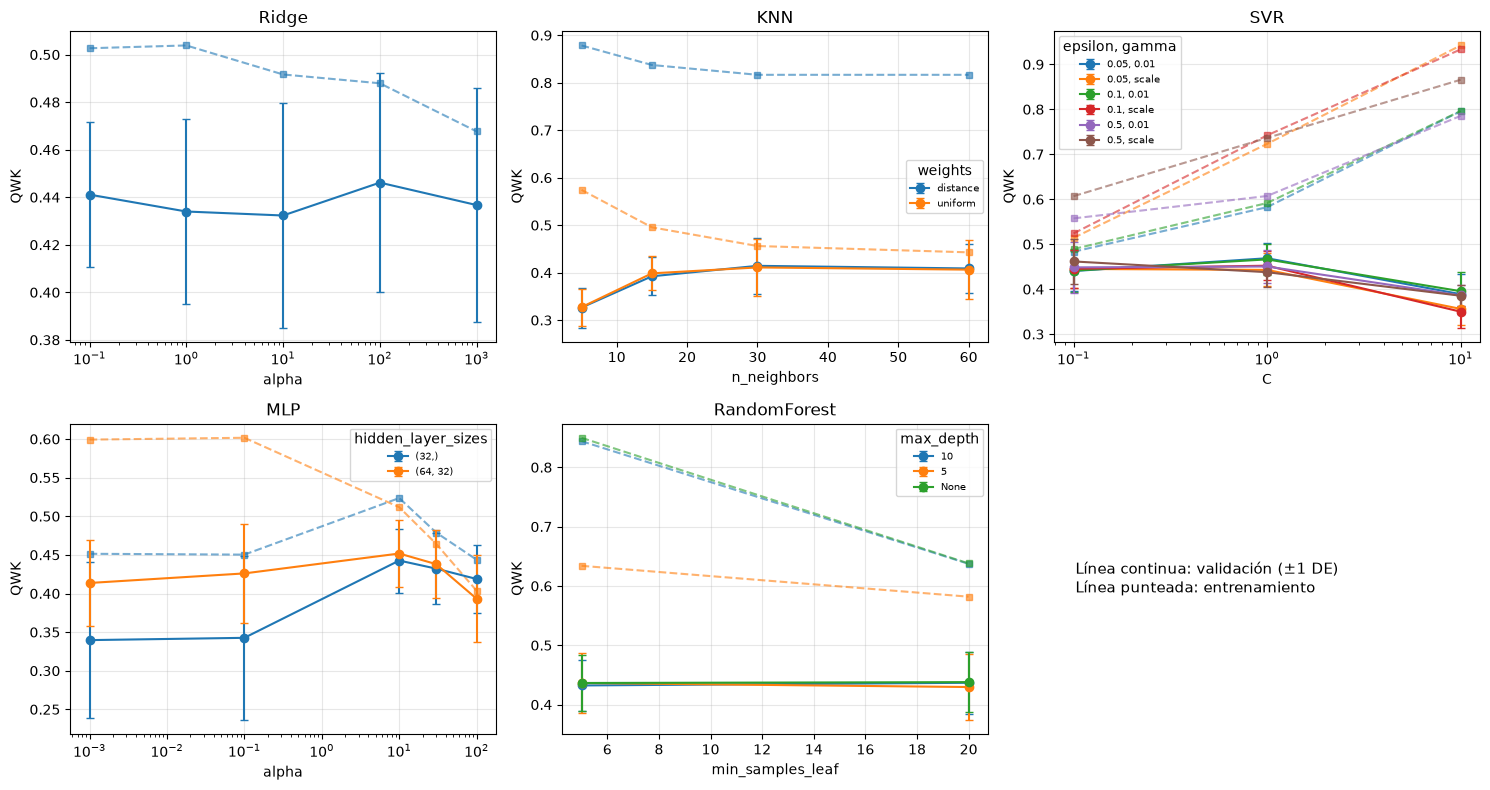

In [29]:
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)

def efecto_df(nombre):
    cvr = pd.DataFrame(resultados_grid[nombre].cv_results_)
    p = pd.DataFrame([{k.replace("estimator__reg__", ""): v for k, v in d.items()}
                      for d in cvr["params"]], dtype=object)       # conserva None y enteros
    return pd.concat([p, cvr[["mean_train_qwk", "mean_test_qwk", "std_test_qwk"]]], axis=1)

# nombre: (parámetro en x, parámetro(s) que separan las curvas, x en escala log)
paneles = {"Ridge": ("alpha", None, True),
           "KNN": ("n_neighbors", ["weights"], False),
           "SVR": ("C", ["epsilon", "gamma"], True),
           "MLP": ("alpha", ["hidden_layer_sizes"], True),
           "RandomForest": ("min_samples_leaf", ["max_depth"], False)}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (nombre, (x, hue, logx)) in zip(axes.ravel(), paneles.items()):
    d = efecto_df(nombre)
    d["_h"] = "" if hue is None else d[hue].astype(str).agg(", ".join, axis=1)
    # dentro del bucle, justo después de crear d["_h"]:
    d[x] = d[x].astype(float)
    for i, (h, g) in enumerate(d.groupby("_h")):
        g = g.sort_values(x); col = f"C{i}"
        ax.errorbar(g[x], g["mean_test_qwk"], yerr=g["std_test_qwk"], marker="o", capsize=3,
                    color=col, label=h or "validación")
        ax.plot(g[x], g["mean_train_qwk"], "--", marker="s", ms=4, color=col, alpha=0.6)
    if logx: ax.set_xscale("log")
    ax.set_xlabel(x); ax.set_ylabel("QWK"); ax.set_title(nombre); ax.grid(alpha=0.3)
    if hue: ax.legend(title=", ".join(hue), fontsize=7)
axes[1, 2].axis("off")
axes[1, 2].text(0.05, 0.5, "Línea continua: validación (±1 DE)\nLínea punteada: entrenamiento",
                fontsize=11, va="center")
plt.tight_layout(); plt.savefig("figures/efecto_hiperparametros.png", dpi=300); plt.show()

**reevaluación con CV repetido, intervalos de confianza y umbrales**

Se evalúa la mejor configuración de cada familia con el cv 5×3 (15 folds, con particiones distintas a las de la búsqueda). Esto mitiga el sesgo optimista y permite guardar cuatro cosas por fold: el QWK, el F1 macro, el recall de la clase 3 y los umbrales aprendidos. Cada modelo guarda su CSV en results/, así que si el kernel se cae no se pierde nada y se salta lo ya hecho.

In [30]:
from sklearn.base import clone
from sklearn.metrics import recall_score

recall3_scorer = make_scorer(recall_score, labels=[3], average="macro", zero_division=0)
scoring_ext = {**scoring, "recall3": recall3_scorer}
familias = ["Ridge", "KNN", "SVR", "MLP", "RandomForest"]

def get_best(nombre):
    if nombre in resultados_grid:
        return resultados_grid[nombre].best_estimator_
    return joblib.load(f"best_{nombre}.joblib")

for nombre in familias:
    f = f"results/cv15_{nombre}.csv"
    if os.path.exists(f):
        print(nombre, "ya existe, se omite"); continue
    t0 = time.time()
    r = cross_validate(clone(get_best(nombre)), X_tr, y_tr, cv=cv, scoring=scoring_ext,
                       return_train_score=True, return_estimator=True, n_jobs=-1)
    thr = np.array([e.thr_ for e in r["estimator"]])
    pd.DataFrame({"qwk_train": r["train_qwk"], "qwk_val": r["test_qwk"],
                  "f1_train": r["train_f1_macro"], "f1_val": r["test_f1_macro"],
                  "recall3_val": r["test_recall3"],
                  "thr1": thr[:, 0], "thr2": thr[:, 1], "thr3": thr[:, 2]}).to_csv(f, index=False)
    print(f"{nombre}: {(time.time()-t0)/60:.1f} min")

Ridge: 0.3 min
KNN: 0.2 min
SVR: 0.3 min
MLP: 0.3 min
RandomForest: 1.8 min


**tabla de resultados, umbrales y comparación estadística**

Los 15 folds comparten datos, así que un intervalo t simple sería demasiado optimista. Se usa el ajuste de Nadeau y Bengio, que suma n_test/n_train = 1/4 a la varianza, tanto para los intervalos como para la prueba pareada. Es la corrección estándar para CV repetido y se puede citar.

In [31]:
from scipy import stats
F = {m: pd.read_csv(f"results/cv15_{m}.csv") for m in familias}
K, RATIO = 15, 1/4

def ic(x):
    x = np.asarray(x); se = x.std(ddof=1) * np.sqrt(1/len(x) + RATIO)
    h = stats.t.ppf(0.975, len(x) - 1) * se
    return x.mean(), x.mean() - h, x.mean() + h

fmt = lambda x: "{:.3f} [{:.3f}, {:.3f}]".format(*ic(x))
tabla = pd.DataFrame({
    "QWK train": {m: f"{F[m].qwk_train.mean():.3f}" for m in familias},
    "QWK val (IC95%)": {m: fmt(F[m].qwk_val) for m in familias},
    "F1 macro val (IC95%)": {m: fmt(F[m].f1_val) for m in familias},
    "Recall clase 3 (IC95%)": {m: fmt(F[m].recall3_val) for m in familias},
})
print(tabla.to_string()); tabla.to_csv("results/tabla_modelos.csv")

print("\nUmbrales por fold (media ± DE):")
print(pd.DataFrame({m: {f"thr{j}": f"{F[m][f'thr{j}'].mean():.2f} ± {F[m][f'thr{j}'].std():.2f}"
                        for j in (1, 2, 3)} for m in familias}).T.to_string())

# Prueba t pareada corregida sobre QWK (mismos folds para todos los modelos)
P = pd.DataFrame(index=familias, columns=familias, dtype=float)
for a in familias:
    for b in familias:
        if a == b: continue
        d = F[a].qwk_val.values - F[b].qwk_val.values
        t = d.mean() / (d.std(ddof=1) * np.sqrt(1/K + RATIO))
        P.loc[a, b] = 2 * stats.t.sf(abs(t), K - 1)
print("\np-valores (QWK, t pareada corregida). Con 10 comparaciones, Bonferroni: p < 0.005")
print(P.round(3).to_string())

             QWK train       QWK val (IC95%)  F1 macro val (IC95%) Recall clase 3 (IC95%)
Ridge            0.485  0.430 [0.378, 0.482]  0.402 [0.355, 0.449]   0.231 [0.031, 0.431]
KNN              0.817  0.400 [0.344, 0.457]  0.362 [0.318, 0.405]  0.100 [-0.091, 0.291]
SVR              0.585  0.456 [0.417, 0.494]  0.403 [0.353, 0.453]  0.184 [-0.042, 0.410]
MLP              0.507  0.444 [0.390, 0.497]  0.397 [0.357, 0.437]   0.260 [0.008, 0.512]
RandomForest     0.637  0.436 [0.389, 0.484]  0.400 [0.339, 0.462]  0.196 [-0.029, 0.421]

Umbrales por fold (media ± DE):
                     thr1         thr2         thr3
Ridge         0.58 ± 0.06  0.95 ± 0.07  1.45 ± 0.08
KNN           0.53 ± 0.04  0.86 ± 0.05  1.30 ± 0.04
SVR           0.35 ± 0.06  0.85 ± 0.04  1.60 ± 0.06
MLP           0.56 ± 0.06  0.90 ± 0.04  1.41 ± 0.08
RandomForest  0.59 ± 0.05  0.93 ± 0.03  1.43 ± 0.06

p-valores (QWK, t pareada corregida). Con 10 comparaciones, Bonferroni: p < 0.005
              Ridge    KNN    SV

**Utilidad opcional:** vaciar el caché del preprocesamiento. Solo hacerlo si se cambia `build_preprocessor` o `num_features`; **no ejecutarlo entre los `run_grid`**.

In [ ]:
# Opcional: borrar el caché (descomentar solo si cambió el preprocesamiento)
# import shutil; shutil.rmtree("cache_prep", ignore_errors=True)